## Settings

In [3]:


import os
import sys
import json
import random
import warnings
import numpy as np
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass


WORK      = Path("/workspace")
SETUP     = WORK / "AMI-diarization-setup"                              
MANIFEST  = WORK / "data_processed" / "prepared" / "manifest_all.csv"   
WAREHOUSE = WORK / "warehouse" / "ami.duckdb"                          


DATABASE_YML = SETUP / "pyannote" / "database.yml"
if not DATABASE_YML.exists():
    raise FileNotFoundError(f"{DATABASE_YML} not found - run notebook 01 first.")
os.environ["PYANNOTE_DATABASE_CONFIG"]  = str(DATABASE_YML)
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"      
warnings.filterwarnings("ignore", message="IProgress not found")



# 2. Are we in the right environment?

print("Python:", sys.version.split()[0], "|", sys.executable)
if "envs/pyannote21" not in sys.executable:
    raise RuntimeError("Wrong kernel! Top-right: choose 'Python (pyannote 2.1)'.")

import torch
import pyannote.audio
print("torch:", torch.__version__, "| pyannote.audio:", pyannote.audio.__version__)
if pyannote.audio.__version__ != "2.1.1":
    raise RuntimeError("Wrong pyannote version - expected 2.1.1.")



# 3. What we evaluate

SPLIT         = "test"                                 
PIPELINE_NAME = "pyannote/speaker-diarization@2.1"     
PROTOCOL_NAME = "AMI.SpeakerDiarization.only_words"   
assert SPLIT in ("test", "dev"), "SPLIT must be 'test' or 'dev'"



# 4. Scoring rules 

COLLAR       = 0.0     
SKIP_OVERLAP = False    



# 5. Published numbers (AMI headset-mix, TEST split)

PUBLISHED       = {"DER": 18.91, "FA": 4.48, "Miss": 9.51, "Conf": 4.91}
REPRO_TOLERANCE = 1.0  

if SPLIT != "test":
    print(f"NOTE: split is '{SPLIT}' - the published numbers are for TEST only, so don't compare with them.")



# 6. Reproducibility: seed, run ID, output folder

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
RESUME_RUN_ID = None    
if RESUME_RUN_ID:
    RUN_ID = RESUME_RUN_ID                            

OUT = WORK / "results" / "pyannote21_baseline" / SPLIT / RUN_ID
(OUT / "rttm").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)



# 7. Hugging Face token (RunPod secret HF_TOKEN, or typed in; never saved)

HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    HF_TOKEN = getpass("Paste your Hugging Face token: ")
    os.environ["HF_TOKEN"] = HF_TOKEN
if not HF_TOKEN:
    raise ValueError("No Hugging Face token given.")



# 8. Save this run's settings 

GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE"
run_info = {
    "run_id": RUN_ID, "split": SPLIT, "pipeline": PIPELINE_NAME, "protocol": PROTOCOL_NAME,
    "collar": COLLAR, "skip_overlap": SKIP_OVERLAP, "seed": SEED,
    "published": PUBLISHED, "tolerance": REPRO_TOLERANCE,
    "python": sys.version.split()[0], "torch": torch.__version__,
    "pyannote_audio": pyannote.audio.__version__, "gpu": GPU_NAME,
}
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2))


print("GPU:", GPU_NAME)
print("Split:", SPLIT, "| Run ID:", RUN_ID, "(UTC)")
print("Results go to:", OUT)

Python: 3.9.23 | /workspace/envs/pyannote21/bin/python
torch: 1.13.1+cu117 | pyannote.audio: 2.1.1
GPU: NVIDIA A40
Split: test | Run ID: 20261021_084955 (UTC)
Results go to: /workspace/results/pyannote21_baseline/test/20261021_084955


## Imports and versions
Loads pyannote and records the exact library versions for this run.

In [5]:
import json
import time
import random
import hashlib
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pyannote.audio
import pyannote.database
import pyannote.metrics
from pyannote.audio import Pipeline
from pyannote.database import get_protocol, FileFinder
from pyannote.database.util import load_rttm
from pyannote.metrics.diarization import DiarizationErrorRate

# Hide warnings from old library versions 
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)



# 1. Library versions

versions = {
    "python":            platform.python_version(),
    "torch":             torch.__version__,
    "pyannote.audio":    pyannote.audio.__version__,
    "pyannote.database": pyannote.database.__version__,
    "pyannote.metrics":  pyannote.metrics.__version__,   
    "gpu":               torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
}
for name, version in versions.items():
    print(f"{name:18s}: {version}")



# 2. Add them to this run's record

run_info["versions"] = versions
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2))
print("\nVersions saved to:", OUT / "run_info.json")

python            : 3.9.23
torch             : 1.13.1+cu117
pyannote.audio    : 2.1.1
pyannote.database : 4.1.3
pyannote.metrics  : 3.2.1
gpu               : NVIDIA A40

Versions saved to: /workspace/results/pyannote21_baseline/test/20261021_084955/run_info.json


### Make pyannote read the AMI setup
`database.yml` (from the AMI setup) tells pyannote where the split lists, answer sheets (RTTM), scoring regions (UEM) and audio are.

In [6]:
# Register the AMI database described in database.yml
from pyannote.database.custom import add_custom_protocols

add_custom_protocols()
known = pyannote.database.get_databases()
print("Databases pyannote knows about:", known)
assert "AMI" in known, "AMI not found - check PYANNOTE_DATABASE_CONFIG in the Settings cell."

Databases pyannote knows about: ['AMI', 'AMI-SDM']


## Load the test meetings
Loads the 16 test meetings and checks them against the official list and Notebook 01's audio fingerprints.

In [7]:
import hashlib
import pandas as pd
from pathlib import Path



# 1. Load the meetings

protocol = get_protocol(PROTOCOL_NAME, preprocessors={"audio": FileFinder()})
files = list(protocol.test()) if SPLIT == "test" else list(protocol.development())


def audio_found(f):

    try:
        return Path(f["audio"]).exists()
    except FileNotFoundError:
        return False


overview = pd.DataFrame([{
    "meeting":            f["uri"],
    "minutes":            round(f["annotated"].duration() / 60, 1),
    "reference_speakers": len(f["annotation"].labels()),
    "audio_found":        audio_found(f),
} for f in files])
print(f"{len(files)} meetings | {overview['minutes'].sum() / 60:.2f} hours of audio")



# 2. Check 1: the right number of meetings

expected_count = {"test": 16, "dev": 18}[SPLIT]
assert len(files) == expected_count, f"Expected {expected_count} meetings, found {len(files)}!"



# 3. Check 2: exactly the meetings of the official list

official = set((SETUP / "lists" / f"{SPLIT}.meetings.txt").read_text().split())
found    = set(overview["meeting"])
assert found == official, f"Lists differ! Missing: {official - found}, extra: {found - official}"


# 4. Check 3: all audio is present

missing = overview.loc[~overview["audio_found"], "meeting"].tolist()
assert not missing, f"Audio missing for {missing} - run notebook 01 (Download Audio Files) again."



# 5. Check 4: same audio files as Notebook 01's manifest (SHA-256 fingerprints)

def sha256_of(path, block_size=8 * 1024 * 1024):
    
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()

manifest = pd.read_csv(MANIFEST).set_index("meeting")
fingerprint_ok = {f["uri"]: sha256_of(f["audio"]) == manifest.loc[f["uri"], "audio_sha256"] for f in files}
overview["same_audio_as_nb01"] = overview["meeting"].map(fingerprint_ok)

different = overview.loc[~overview["same_audio_as_nb01"], "meeting"].tolist()
assert not different, f"Audio differs from Notebook 01's manifest for {different}!"


print(f"All {len(files)} meetings match the official list, have audio, "
      f"and are the same files as Notebook 01's manifest.")
overview

16 meetings | 9.06 hours of audio
All 16 meetings match the official list, have audio, and are the same files as Notebook 01's manifest.


,meeting,minutes,reference_speakers,audio_found,same_audio_as_nb01
0,IS1009a,14.0,4,True,True
1,IS1009b,34.2,4,True,True
2,IS1009c,30.3,4,True,True
3,IS1009d,32.4,4,True,True
4,ES2004a,17.5,4,True,True
5,ES2004b,39.1,4,True,True
6,ES2004c,38.9,4,True,True
7,ES2004d,37.0,4,True,True
8,TS3003a,25.1,4,True,True
9,TS3003b,36.8,4,True,True


## Load the pipeline
Loads pyannote/speaker-diarization@2.1 and checks: on GPU, same scoring rules, same hyper-parameters as published.

In [8]:
import json
import time
import random
import yaml
import numpy as np
import torch
import huggingface_hub.constants
import huggingface_hub.file_download

# Normal downloader 
huggingface_hub.constants.HF_HUB_ENABLE_HF_TRANSFER = False
huggingface_hub.file_download.HF_HUB_ENABLE_HF_TRANSFER = False


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)



# 1. Load

start = time.time()
pipeline = Pipeline.from_pretrained(PIPELINE_NAME, use_auth_token=HF_TOKEN)
if pipeline is None:
    raise RuntimeError("Pipeline did not load - check the token and model access.")
print(f"Pipeline loaded in {time.time() - start:.1f} s")



# 2. Check: both models are on the GPU

print("Segmentation model on:", pipeline._segmentation.device)
print("Embedding model on:   ", pipeline._embedding.device)
assert "cuda" in str(pipeline._segmentation.device), "Segmentation model is not on the GPU!"
assert "cuda" in str(pipeline._embedding.device),    "Embedding model is not on the GPU!"



# 3. Check: the pipeline was tuned for the same scoring rules we use

print("\nPipeline scoring rules:", pipeline.der_variant)
assert pipeline.der_variant["collar"] == COLLAR, "Pipeline collar differs from our COLLAR!"
assert pipeline.der_variant["skip_overlap"] == SKIP_OVERLAP, "Pipeline skip_overlap differs from ours!"



# 4. Check: hyper-parameters = the published config.yaml 
params = pipeline.parameters(instantiated=True)
print("Pipeline hyper-parameters:", json.dumps(params, indent=2, default=float))

saved_configs = sorted((WORK / "logs").glob("pipeline_config_*.yaml"))
if saved_configs:
    published_params = yaml.safe_load(saved_configs[-1].read_text())["params"]
    assert params == published_params, (f"Loaded hyper-parameters differ from {saved_configs[-1].name}!\n"
                                        f"published: {published_params}")
    print(f"Hyper-parameters match the published config ({saved_configs[-1].name})")
else:
    print("NOTE: no pipeline_config_*.yaml in logs/ - run Notebook 01's Hugging Face check to compare.")



# 5. Save

with open(OUT / "pipeline_settings.json", "w") as f:
    json.dump({"pipeline": PIPELINE_NAME, "seed": SEED, "der_variant": pipeline.der_variant,
               "hyper_parameters": params, "versions": versions}, f, indent=2, default=float)
print("Saved:", OUT / "pipeline_settings.json")

torchvision is not available - cannot save figures
/workspace/envs/pyannote21/lib/python3.9/site-packages/pyannote/audio/core/model.py:426: UserWarning: Model was trained with pyannote.audio 0.0.1, yours is 2.1.1. Bad things will probably happen unless you update pyannote.audio to 0.x.
  warnings.warn(


Pipeline loaded in 7.6 s
Segmentation model on: cuda:0
Embedding model on:    cuda:0

Pipeline scoring rules: {'collar': 0.0, 'skip_overlap': False}
Pipeline hyper-parameters: {
  "segmentation": {
    "min_duration_off": 0.5817029604921046,
    "threshold": 0.4442333667381752
  },
  "clustering": {
    "method": "centroid",
    "min_cluster_size": 15,
    "threshold": 0.7153814381597874
  }
}
Hyper-parameters match the published config (pipeline_config_20261021_081634.yaml)
Saved: /workspace/results/pyannote21_baseline/test/20261021_084955/pipeline_settings.json


## Diarize and score every meeting
Runs the pipeline on each test meeting, saves its answer (RTTM), and scores DER — overall, in overlap, and elsewhere.

In [9]:
import time
import pandas as pd
from pyannote.core import Annotation


metric          = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)   
der_overlap     = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)   
der_non_overlap = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)   

rows = []
hypotheses = {}   

for i, file in enumerate(files, start=1):
    meeting       = file["uri"]
    reference     = file["annotation"]
    rttm_file     = OUT / "rttm" / f"{meeting}.rttm"
    audio_seconds = file["annotated"].duration()

 
    # 1. Get the pipeline's answer 
   
    if rttm_file.exists():
        hypothesis = load_rttm(rttm_file).get(meeting, Annotation(uri=meeting))   
        seconds = None
    else:
        start = time.perf_counter()
        hypothesis = pipeline({"uri": meeting, "audio": file["audio"]})
        seconds = time.perf_counter() - start

        # Write to a temporary file first, rename only when complete
        temporary = rttm_file.with_name(rttm_file.name + ".part")
        with open(temporary, "w") as out:
            hypothesis.write_rttm(out)
        temporary.replace(rttm_file)

    hypotheses[meeting] = hypothesis


    # 2. Score: whole recording, with the three error parts
    
    d = metric(reference, hypothesis, uem=file["annotated"], detailed=True)
    total = d["total"]    # reference speech time (s)

   
    # 3. Score: only overlapped speech, and everything else
 
    overlap_region     = reference.get_timeline().get_overlap().crop(file["annotated"])
    non_overlap_region = overlap_region.gaps(support=file["annotated"])
    ov  = der_overlap(reference, hypothesis, uem=overlap_region)
    non = der_non_overlap(reference, hypothesis, uem=non_overlap_region)

    rows.append({
        "meeting":              meeting,
        "DER_%":                100 * d["diarization error rate"],
        "missed_%":             100 * d["missed detection"] / total,
        "false_alarm_%":        100 * d["false alarm"] / total,
        "confusion_%":          100 * d["confusion"] / total,
        "DER_overlap_%":        100 * ov,
        "DER_non_overlap_%":    100 * non,
        "overlap_min":          overlap_region.duration() / 60,
        "reference_speech_min": total / 60,
        "predicted_speakers":   len(hypothesis.labels()),
        "reference_speakers":   len(reference.labels()),
        "processing_min":       None if seconds is None else seconds / 60,
        "RTF":                  None if seconds is None else seconds / audio_seconds,
    })

    timing = ("loaded from disk" if seconds is None
              else f"took {seconds / 60:.1f} min, RTF {seconds / audio_seconds:.3f}")
    print(f"[{i:2d}/{len(files)}] {meeting}: DER {rows[-1]['DER_%']:5.2f}% "
          f"| overlap DER {rows[-1]['DER_overlap_%']:5.1f}% "
          f"| speakers {rows[-1]['predicted_speakers']} vs {rows[-1]['reference_speakers']}  ({timing})")

results = pd.DataFrame(rows)
print("\nAll meetings done ✓")

[ 1/16] IS1009a: DER 20.86% | overlap DER  38.3% | speakers 4 vs 4  (took 0.9 min, RTF 0.068)
[ 2/16] IS1009b: DER 13.32% | overlap DER  39.2% | speakers 5 vs 4  (took 2.0 min, RTF 0.059)
[ 3/16] IS1009c: DER 11.90% | overlap DER  46.0% | speakers 6 vs 4  (took 1.8 min, RTF 0.060)
[ 4/16] IS1009d: DER 16.78% | overlap DER  38.3% | speakers 4 vs 4  (took 2.1 min, RTF 0.064)
[ 5/16] ES2004a: DER 19.19% | overlap DER  35.9% | speakers 4 vs 4  (took 1.0 min, RTF 0.055)
[ 6/16] ES2004b: DER 13.37% | overlap DER  34.2% | speakers 5 vs 4  (took 2.3 min, RTF 0.058)
[ 7/16] ES2004c: DER 13.96% | overlap DER  32.6% | speakers 5 vs 4  (took 2.3 min, RTF 0.059)
[ 8/16] ES2004d: DER 20.93% | overlap DER  32.9% | speakers 6 vs 4  (took 2.2 min, RTF 0.060)
[ 9/16] TS3003a: DER 19.18% | overlap DER  45.4% | speakers 2 vs 4  (took 1.4 min, RTF 0.055)
[10/16] TS3003b: DER 12.37% | overlap DER  34.8% | speakers 4 vs 4  (took 2.2 min, RTF 0.061)
[11/16] TS3003c: DER 14.94% | overlap DER  36.2% | speakers 

## Overall DER vs the paper
Pooled DER over all test meetings, compared with the published 18.91%, with a bootstrap range over meetings.

In [10]:
import json
import numpy as np
import pandas as pd



# 1. Pooled DER and its three parts

report       = metric.report(display=False)        
total_row    = report.loc["TOTAL"]
total_speech = total_row[("total", "")]

ours = {
    "DER":  abs(metric) * 100,
    "Miss": 100 * total_row[("missed detection", "")] / total_speech,
    "FA":   100 * total_row[("false alarm", "")]      / total_speech,
    "Conf": 100 * total_row[("confusion", "")]        / total_speech,
}



# 2. Compare with the published numbers

comparison = pd.DataFrame({"ours_%": {k: round(v, 2) for k, v in ours.items()}})
gap = reproduced = None
if SPLIT == "test":
    comparison["published_%"] = [PUBLISHED[k] for k in comparison.index]
    comparison["gap_points"]  = (comparison["ours_%"] - comparison["published_%"]).round(2)
    gap = ours["DER"] - PUBLISHED["DER"]
    reproduced = abs(gap) <= REPRO_TOLERANCE

print(comparison.to_string(), "\n")



# 3. Spread: bootstrap over meetings 

per_meeting = report.drop(index="TOTAL")
errors = (per_meeting[("missed detection", "")] + per_meeting[("false alarm", "")]
          + per_meeting[("confusion", "")]).values
speech = per_meeting[("total", "")].values

rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    pick = rng.integers(0, len(speech), len(speech))       
    boot.append(100 * errors[pick].sum() / speech[pick].sum())
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])



# 4. Pooled DER in overlapped speech vs everywhere else

overlap_der     = abs(der_overlap) * 100
non_overlap_der = abs(der_non_overlap) * 100


# 5. Summary

print(f"Overall DER       : {ours['DER']:.2f}%  (95% range over meetings: {ci_low:.2f} - {ci_high:.2f}%)")
if SPLIT == "test":
    print(f"Published DER     : {PUBLISHED['DER']}%  ->  gap {gap:+.2f} points  "
          f"->  reproduced (within ±{REPRO_TOLERANCE}): {reproduced}")
print(f"DER in overlap    : {overlap_der:.2f}%")
print(f"DER elsewhere     : {non_overlap_der:.2f}%")



# 6. Save everything to this run's folder

comparison.to_csv(OUT / "der_comparison.csv")
results.to_csv(OUT / "per_meeting_results.csv", index=False)
report.to_csv(OUT / "pyannote_metric_report.csv")

summary = {
    "run_id": RUN_ID, "split": SPLIT, "pipeline": PIPELINE_NAME, "gpu": GPU_NAME,
    "meetings": len(results),
    "der_%": round(ours["DER"], 2), "miss_%": round(ours["Miss"], 2),
    "fa_%": round(ours["FA"], 2), "conf_%": round(ours["Conf"], 2),
    "der_95_range_%": [round(ci_low, 2), round(ci_high, 2)],
    "spread_method": "bootstrap over meetings (2000 resamples); pipeline is deterministic",
    "der_overlap_%": round(overlap_der, 2), "der_non_overlap_%": round(non_overlap_der, 2),
    "published_der_%": PUBLISHED["DER"] if SPLIT == "test" else None,
    "gap_points": None if gap is None else round(gap, 2),
    "reproduced": reproduced,
    "processing_min_total": round(results["processing_min"].sum(), 1),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("\nSaved to:", OUT)

results.round(2).sort_values("DER_%", ascending=False)       

      ours_%  published_%  gap_points
DER    19.11        18.91        0.20
Miss    8.65         9.51       -0.86
FA      5.29         4.48        0.81
Conf    5.17         4.91        0.26 

Overall DER       : 19.11%  (95% range over meetings: 16.34 - 21.71%)
Published DER     : 18.91%  ->  gap +0.20 points  ->  reproduced (within ±1.0): True
DER in overlap    : 37.58%
DER elsewhere     : 12.28%

Saved to: /workspace/results/pyannote21_baseline/test/20261021_084955


,meeting,DER_%,missed_%,false_alarm_%,confusion_%,DER_overlap_%,DER_non_overlap_%,overlap_min,reference_speech_min,predicted_speakers,reference_speakers,processing_min,RTF
15,EN2002d,27.15,14.30,5.06,7.78,40.54,13.99,9.65,44.60,6,4,2.27,0.06
13,EN2002b,25.68,10.38,5.28,10.01,40.26,14.18,6.50,32.39,7,4,1.86,0.06
12,EN2002a,24.89,11.94,5.78,7.17,35.39,16.06,8.66,42.17,5,4,2.21,0.06
11,TS3003d,23.02,11.63,7.16,4.23,35.88,19.79,3.31,34.51,5,4,2.63,0.06
14,EN2002c,21.97,11.02,2.45,8.50,38.53,10.49,10.51,55.73,6,3,3.23,0.07
7,ES2004d,20.93,8.06,7.47,5.40,32.94,16.43,4.32,33.45,6,4,2.21,0.06
0,IS1009a,20.86,7.77,7.68,5.41,38.30,15.09,1.37,11.60,4,4,0.95,0.07
4,ES2004a,19.19,11.55,4.63,3.01,35.92,12.61,2.07,15.39,4,4,0.96,0.06
8,TS3003a,19.18,10.13,4.41,4.64,45.42,16.58,0.75,17.10,2,4,1.38,0.06
3,IS1009d,16.78,7.28,5.38,4.11,38.25,11.31,2.70,28.98,4,4,2.08,0.06


## Overlap analysis and Model 1 target
DER inside vs outside overlapped speech, and the overlap target Model 1 must beat.

In [11]:
import json

overlap_der     = abs(der_overlap) * 100
non_overlap_der = abs(der_non_overlap) * 100



# 1. How much of the speech is overlapped? 

speech_seconds  = sum(f["annotation"].get_timeline().support().crop(f["annotated"]).duration() for f in files)
overlap_seconds = results["overlap_min"].sum() * 60
overlap_share   = 100 * overlap_seconds / speech_seconds



# 2. Results

print(f"Overlapped speech is {overlap_share:.2f}% of speech time  (Notebook 01 found 14.58% for test)")
print(f"DER in overlapped speech : {overlap_der:.2f}%")
print(f"DER outside overlap      : {non_overlap_der:.2f}%   (includes silence)")
print(f"-> DER is {overlap_der / non_overlap_der:.1f}x higher when people overlap")



# 3. Model 1 target 

model1_target = 0.9 * overlap_der
print(f"\nModel 1 target (AI2): overlap DER <= {model1_target:.2f}%")



# 4. Add to this run's summary

summary_file = OUT / "summary.json"
summary = json.loads(summary_file.read_text())
summary.update({
    "overlap_share_of_speech_%":      round(overlap_share, 2),
    "der_overlap_to_non_overlap_ratio": round(overlap_der / non_overlap_der, 2),
    "model1_target_overlap_der_%":    round(model1_target, 2),
})
summary_file.write_text(json.dumps(summary, indent=2, default=float))
print("Added to:", summary_file)

Overlapped speech is 14.58% of speech time  (Notebook 01 found 14.58% for test)
DER in overlapped speech : 37.58%
DER outside overlap      : 12.28%   (includes silence)
-> DER is 3.1x higher when people overlap

Model 1 target (AI2): overlap DER <= 33.82%
Added to: /workspace/results/pyannote21_baseline/test/20261021_084955/summary.json


## Speaker-count errors
How often the model predicts too many or too few speakers, and how much speech goes to "extra" speakers.

In [12]:
import numpy as np



# 1. Wrong number of speakers per meeting

results["speaker_count_error"] = results["predicted_speakers"] - results["reference_speakers"]

counts = {
    "correct number":   int((results["speaker_count_error"] == 0).sum()),
    "too many (extra)": int((results["speaker_count_error"] > 0).sum()),
    "too few":          int((results["speaker_count_error"] < 0).sum()),
}
print("Meetings by speaker-count result:", counts)



# 2. How much speech went to EXTRA speakers

mapper = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)

extra_minutes = {}
for file in files:
    meeting    = file["uri"]
    hypothesis = hypotheses[meeting].crop(file["annotated"])
    mapping    = mapper.optimal_mapping(file["annotation"], hypothesis)   # predicted label -> real person
    unmatched  = [label for label in hypothesis.labels() if label not in mapping]
    extra_minutes[meeting] = sum(hypothesis.label_duration(label) for label in unmatched) / 60

results["extra_speaker_min"] = results["meeting"].map(extra_minutes)
results["extra_speaker_%"]   = 100 * results["extra_speaker_min"] / results["reference_speech_min"]



# 3. Confusion by speaker-count result

by_type = results.assign(result=np.sign(results["speaker_count_error"])
                                  .map({0: "correct", 1: "too many", -1: "too few"}))
group_stats = by_type.groupby("result")["confusion_%"].agg(["count", "mean"]).round(2)
print("\nAverage confusion (% of speech) by speaker-count result:")
print(group_stats.to_string())
if (group_stats["count"] < 3).any():
    print("NOTE: groups with fewer than 3 meetings are single cases, not averages - don't generalise.")



# 4. Save 

results.to_csv(OUT / "per_meeting_results.csv", index=False)
print("\nUpdated:", OUT / "per_meeting_results.csv")

results[["meeting", "reference_speakers", "predicted_speakers", "speaker_count_error",
         "extra_speaker_min", "extra_speaker_%", "confusion_%", "DER_%"]] \
    .sort_values("speaker_count_error", ascending=False).round(2)

Meetings by speaker-count result: {'correct number': 4, 'too many (extra)': 11, 'too few': 1}

Average confusion (% of speech) by speaker-count result:
          count  mean
result               
correct       4  3.43
too few       1  4.64
too many     11  5.38
NOTE: groups with fewer than 3 meetings are single cases, not averages - don't generalise.

Updated: /workspace/results/pyannote21_baseline/test/20261021_084955/per_meeting_results.csv


,meeting,reference_speakers,predicted_speakers,speaker_count_error,extra_speaker_min,extra_speaker_%,confusion_%,DER_%
13,EN2002b,4,7,3,2.75,8.48,10.01,25.68
14,EN2002c,3,6,3,3.82,6.86,8.50,21.97
2,IS1009c,4,6,2,0.96,3.63,3.72,11.90
7,ES2004d,4,6,2,0.93,2.79,5.40,20.93
15,EN2002d,4,6,2,2.17,4.86,7.78,27.15
1,IS1009b,4,5,1,0.84,2.53,4.09,13.32
5,ES2004b,4,5,1,0.60,1.62,2.80,13.37
6,ES2004c,4,5,1,0.76,2.03,3.38,13.96
10,TS3003c,4,5,1,0.29,0.92,2.08,14.94
11,TS3003d,4,5,1,0.58,1.68,4.23,23.02


## DER parts per meeting
Missed speech, false alarm, and confusion for each test meeting, worst first.

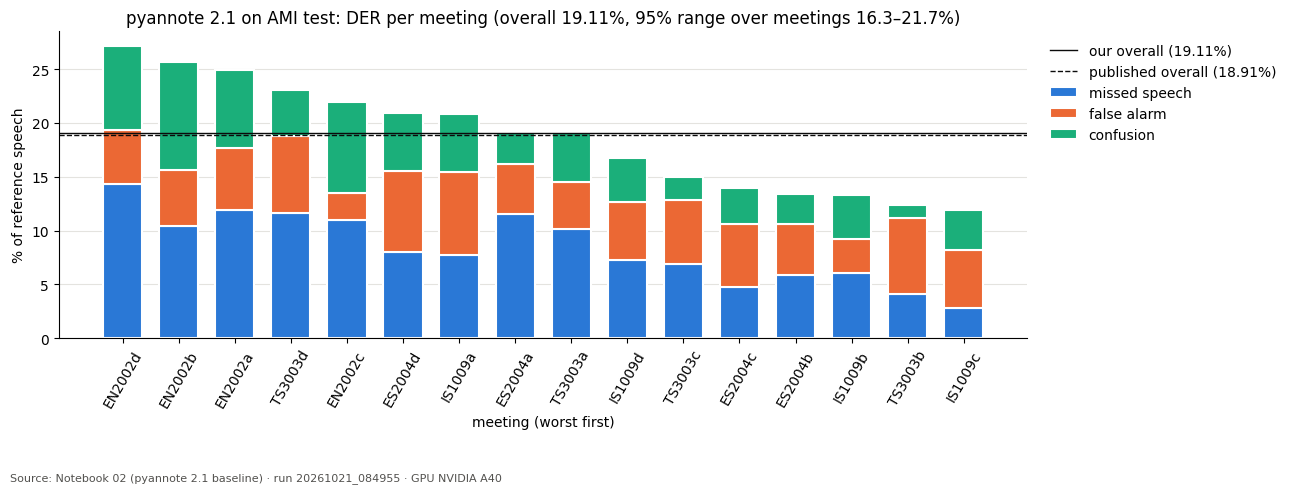

Saved: /workspace/results/pyannote21_baseline/test/20261021_084955/figures/der_per_meeting.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt

PART_COLORS = {"missed_%": "#2a78d6", "false_alarm_%": "#eb6834", "confusion_%": "#1baf7a"}
PART_LABELS = {"missed_%": "missed speech", "false_alarm_%": "false alarm", "confusion_%": "confusion"}
INK, NEUTRAL = "#0b0b0b", "#52514e"

ordered = results.sort_values("DER_%", ascending=False)

fig, ax = plt.subplots(figsize=(13, 4.5))



# 1. Stacked bars: one colour per error type

bottom = np.zeros(len(ordered))
for column, color in PART_COLORS.items():
    ax.bar(ordered["meeting"], ordered[column], bottom=bottom, width=0.7,
           color=color, edgecolor="white", linewidth=1.5, label=PART_LABELS[column])
    bottom = bottom + ordered[column].values        



# 2. Reference lines: our pooled DER and the published one

ax.axhline(ours["DER"], color=INK, linestyle="-", linewidth=1,
           label=f"our overall ({ours['DER']:.2f}%)")
if SPLIT == "test":
    ax.axhline(PUBLISHED["DER"], color=INK, linestyle="--", linewidth=1,
               label=f"published overall ({PUBLISHED['DER']}%)")



# 3. Labels, legend outside the plot, quiet axes

ax.set_xlabel("meeting (worst first)")
ax.set_ylabel("% of reference speech")
ax.set_title(f"pyannote 2.1 on AMI {SPLIT}: DER per meeting "
             f"(overall {ours['DER']:.2f}%, 95% range over meetings {ci_low:.1f}–{ci_high:.1f}%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
plt.xticks(rotation=60)

fig.text(0.01, -0.08, f"Source: Notebook 02 (pyannote 2.1 baseline) · run {RUN_ID} · GPU {GPU_NAME}",
         fontsize=8, color=NEUTRAL)



# 4. Save

plt.tight_layout()
figure_file = OUT / "figures" / "der_per_meeting.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_file)

## DER inside vs outside overlap, per meeting
In every meeting, errors are much higher where people talk at the same time.

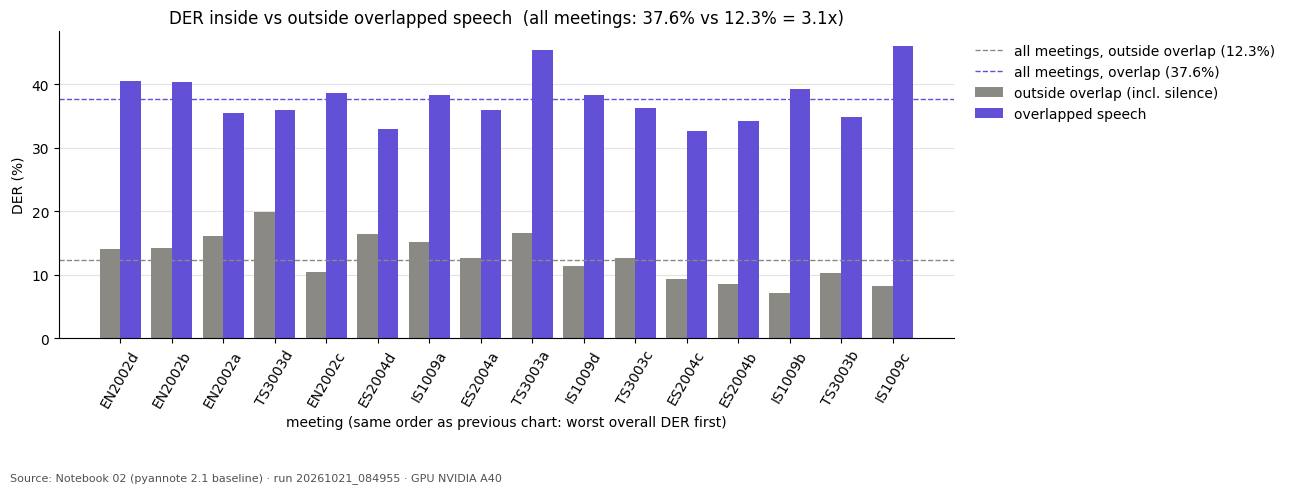

Saved: /workspace/results/pyannote21_baseline/test/20261021_084955/figures/der_overlap_vs_outside.png


In [14]:
import numpy as np
import matplotlib.pyplot as plt

OUTSIDE_COLOR = "#8a8984"  
OVERLAP_COLOR = "#6250d6"   
INK, NEUTRAL  = "#0b0b0b", "#52514e"

fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(ordered))



# 1. Two bars per meeting

ax.bar(x - 0.2, ordered["DER_non_overlap_%"], width=0.4, color=OUTSIDE_COLOR,
       label="outside overlap (incl. silence)")
ax.bar(x + 0.2, ordered["DER_overlap_%"], width=0.4, color=OVERLAP_COLOR,
       label="overlapped speech")



# 2. Pooled values over all meetings as reference lines

ax.axhline(non_overlap_der, color=OUTSIDE_COLOR, linestyle="--", linewidth=1,
           label=f"all meetings, outside overlap ({non_overlap_der:.1f}%)")
ax.axhline(overlap_der, color=OVERLAP_COLOR, linestyle="--", linewidth=1,
           label=f"all meetings, overlap ({overlap_der:.1f}%)")



# 3. Labels, legend outside, quiet axes

ax.set_xticks(x)
ax.set_xticklabels(ordered["meeting"], rotation=60)
ax.set_xlabel("meeting (same order as previous chart: worst overall DER first)")
ax.set_ylabel("DER (%)")
ax.set_title(f"DER inside vs outside overlapped speech  "
             f"(all meetings: {overlap_der:.1f}% vs {non_overlap_der:.1f}% = "
             f"{overlap_der / non_overlap_der:.1f}x)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)

fig.text(0.01, -0.08, f"Source: Notebook 02 (pyannote 2.1 baseline) · run {RUN_ID} · GPU {GPU_NAME}",
         fontsize=8, color=NEUTRAL)



# 4. Save

plt.tight_layout()
figure_file = OUT / "figures" / "der_overlap_vs_outside.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_file)

## Timeline of the hardest meeting
Who really spoke vs the model's answer. Grey bands = overlap; striped rows = speakers the model invented.

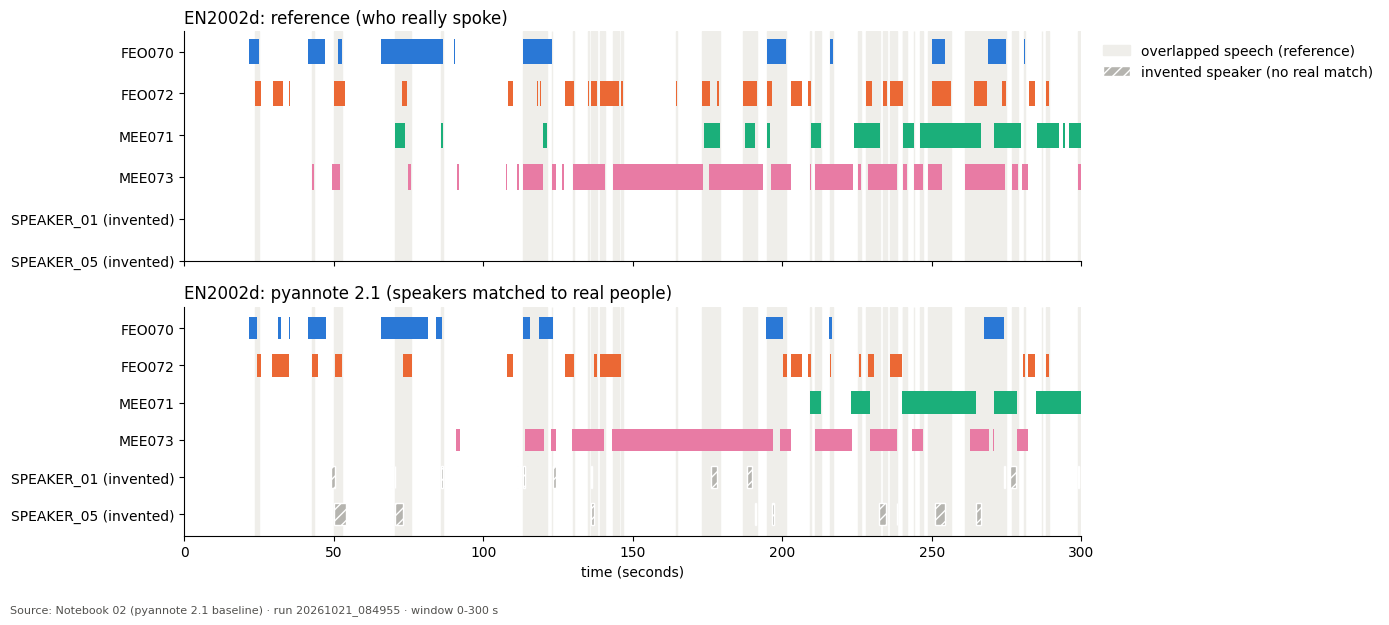

Model speaker -> real person: {'SPEAKER_00': 'MEE073', 'SPEAKER_02': 'FEO070', 'SPEAKER_03': 'FEO072', 'SPEAKER_04': 'MEE071'}
Invented speakers (no real match): ['SPEAKER_01', 'SPEAKER_05']
Saved: /workspace/results/pyannote21_baseline/test/20261021_084955/figures/timeline_EN2002d_0-300s.png


In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

WINDOW = (0, 300)     

PEOPLE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4", "#6250d6", "#eda100"]
EXTRA_COLOR   = "#b5b4af"
OVERLAP_SHADE = "#efeeea"
NEUTRAL       = "#52514e"



# 1. The hardest meeting and its answers

worst      = ordered.iloc[0]["meeting"]
file       = next(f for f in files if f["uri"] == worst)
reference  = file["annotation"]
hypothesis = hypotheses[worst]


mapping = mapper.optimal_mapping(reference, hypothesis, uem=file["annotated"])
hypothesis_matched = hypothesis.rename_labels(mapping)


real_people = sorted(reference.labels())
extra       = sorted(set(hypothesis_matched.labels()) - set(real_people))
all_labels  = real_people + extra
colors      = {label: PEOPLE_COLORS[i % len(PEOPLE_COLORS)] for i, label in enumerate(real_people)}
colors.update({label: EXTRA_COLOR for label in extra})

overlap_region = reference.get_timeline().get_overlap()


# 2. Draw one panel

def draw(ax, annotation, title):
  
    for segment in overlap_region:                                 
        if segment.end > WINDOW[0] and segment.start < WINDOW[1]:
            ax.axvspan(segment.start, segment.end, color=OVERLAP_SHADE, zorder=0)

    for row, label in enumerate(all_labels):
        if label not in annotation.labels():
            continue
        for segment in annotation.label_timeline(label):
            if segment.end > WINDOW[0] and segment.start < WINDOW[1]:
                ax.barh(row, segment.duration, left=segment.start, height=0.6,
                        color=colors[label], hatch="///" if label in extra else None,
                        edgecolor="white" if label in extra else None, zorder=2)

    ax.set_yticks(range(len(all_labels)))
    ax.set_yticklabels([f"{l} (invented)" if l in extra else l for l in all_labels])
    ax.invert_yaxis()                                        
    ax.set_xlim(*WINDOW)
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)



# 3. Reference on top, model below

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
draw(axes[0], reference,          f"{worst}: reference (who really spoke)")
draw(axes[1], hypothesis_matched, f"{worst}: pyannote 2.1 (speakers matched to real people)")
axes[1].set_xlabel("time (seconds)")

legend_items = [Patch(color=OVERLAP_SHADE, label="overlapped speech (reference)")]
if extra:
    legend_items.append(Patch(facecolor=EXTRA_COLOR, hatch="///", edgecolor="white",
                              label="invented speaker (no real match)"))
axes[0].legend(handles=legend_items, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

fig.text(0.01, -0.03, f"Source: Notebook 02 (pyannote 2.1 baseline) · run {RUN_ID} · "
                      f"window {WINDOW[0]}-{WINDOW[1]} s", fontsize=8, color=NEUTRAL)



# 4. Save

plt.tight_layout()
figure_file = OUT / "figures" / f"timeline_{worst}_{WINDOW[0]}-{WINDOW[1]}s.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()

print("Model speaker -> real person:", mapping)
if extra:
    print("Invented speakers (no real match):", extra)
print("Saved:", figure_file)

## Do invented speakers come from overlap?
Share of invented-speaker time that falls inside overlapped speech.

In [16]:
inside, total_extra = 0.0, 0.0
for file in files:
    reference  = file["annotation"]
    hypothesis = hypotheses[file["uri"]].crop(file["annotated"])
    mapping    = mapper.optimal_mapping(reference, hypothesis)
    overlap    = reference.get_timeline().get_overlap()

    for label in hypothesis.labels():
        if label not in mapping:                                  # invented speaker
            timeline = hypothesis.label_timeline(label)
            total_extra += timeline.duration()
            inside      += timeline.crop(overlap).duration()

print(f"Invented-speaker time: {total_extra / 60:.1f} min")
print(f"  of which inside overlapped speech: {100 * inside / total_extra:.1f}%")
print(f"  (overlap is only {overlap_share:.1f}% of all speech time)")

Invented-speaker time: 15.0 min
  of which inside overlapped speech: 64.9%
  (overlap is only 14.6% of all speech time)


In [17]:
summary_file = OUT / "summary.json"
summary = json.loads(summary_file.read_text())
summary.update({
    "invented_speaker_min":              round(total_extra / 60, 1),
    "invented_speaker_inside_overlap_%": round(100 * inside / total_extra, 1),
})
summary_file.write_text(json.dumps(summary, indent=2, default=float))
print("Added to:", summary_file)

Added to: /workspace/results/pyannote21_baseline/test/20261021_084955/summary.json


## Final summary
All headline numbers of this run in one file: `summary.json`.

In [18]:
import json

# 1. Speed over all meetings that were actually run 

measured = results.dropna(subset=["processing_min"])
measured_meetings  = set(measured["meeting"])
audio_min_measured = sum(f["annotated"].duration() for f in files if f["uri"] in measured_meetings) / 60
overall_rtf = measured["processing_min"].sum() / audio_min_measured if len(measured) else None


# 2. Add to the existing summary 

summary_file = OUT / "summary.json"
summary = json.loads(summary_file.read_text())

summary.update({
    "seed":              SEED,
    "protocol":          f"{PROTOCOL_NAME} ({SPLIT}, {len(files)} meetings)",
    "scoring":           {"collar": COLLAR, "skip_overlap": SKIP_OVERLAP,
                          "uem": "official AMI diarization setup"},
    "published_parts_%": PUBLISHED if SPLIT == "test" else None,
    "tolerance_points":  REPRO_TOLERANCE,
    "speaker_count":     counts,
    "overall_rtf":       round(overall_rtf, 4) if overall_rtf is not None else None,
    "data_check":        "audio SHA-256 matches notebook 01 manifest",
    "versions":          versions,
})
summary_file.write_text(json.dumps(summary, indent=2, default=float))


# 3. Show the complete summary and the files in this run's folder

print(json.dumps(summary, indent=2, default=float))
print("\nSaved in:", OUT)
print("Files:", sorted(p.name for p in OUT.iterdir()))

{
  "run_id": "20261021_084955",
  "split": "test",
  "pipeline": "pyannote/speaker-diarization@2.1",
  "gpu": "NVIDIA A40",
  "meetings": 16,
  "der_%": 19.11,
  "miss_%": 8.65,
  "fa_%": 5.29,
  "conf_%": 5.17,
  "der_95_range_%": [
    16.34,
    21.71
  ],
  "spread_method": "bootstrap over meetings (2000 resamples); pipeline is deterministic",
  "der_overlap_%": 37.58,
  "der_non_overlap_%": 12.28,
  "published_der_%": 18.91,
  "gap_points": 0.2,
  "reproduced": true,
  "processing_min_total": 32.9,
  "overlap_share_of_speech_%": 14.58,
  "der_overlap_to_non_overlap_ratio": 3.06,
  "model1_target_overlap_der_%": 33.82,
  "invented_speaker_min": 15.0,
  "invented_speaker_inside_overlap_%": 64.9,
  "seed": 42,
  "protocol": "AMI.SpeakerDiarization.only_words (test, 16 meetings)",
  "scoring": {
    "collar": 0.0,
    "skip_overlap": false,
    "uem": "official AMI diarization setup"
  },
  "published_parts_%": {
    "DER": 18.91,
    "FA": 4.48,
    "Miss": 9.51,
    "Conf": 4.91
  

## Save results to the warehouse
Per-meeting results and the benchmark row go into DuckDB — every future model is added the same way.

In [23]:
import json
import duckdb
import pandas as pd

MODEL_NAME = "pyannote2.1_baseline"


STANDARD_COLUMNS = ["meeting", "DER_%", "missed_%", "false_alarm_%", "confusion_%",
                    "DER_overlap_%", "DER_non_overlap_%", "reference_speech_min",
                    "predicted_speakers", "reference_speakers"]

per_meeting_rows = results[STANDARD_COLUMNS].assign(model=MODEL_NAME, split=SPLIT, run_id=RUN_ID)

summary = json.loads((OUT / "summary.json").read_text())
benchmark_row = pd.DataFrame([{
    "model":        MODEL_NAME,
    "type":         "baseline (reproduced)",
    "split":        SPLIT,
    "run_id":       RUN_ID,
    "meetings":     summary["meetings"],
    "der_%":        summary["der_%"],
    "der_95_low":   summary["der_95_range_%"][0],
    "der_95_high":  summary["der_95_range_%"][1],
    "der_overlap_%": summary["der_overlap_%"],
    "published_%":  summary["published_der_%"],
    "gap_points":   summary["gap_points"],
    "runs":         "1 (deterministic)",
    "gpu":          summary["gpu"],
    "gpu_min":      summary["processing_min_total"],
}])


def save(con, table_name, rows):

    con.register("incoming", rows)
    con.execute(f"CREATE TABLE IF NOT EXISTS {table_name} AS SELECT * FROM incoming WHERE 1 = 0")
    con.execute(f"DELETE FROM {table_name} WHERE run_id = ? AND model = ?", [RUN_ID, MODEL_NAME])
    con.execute(f"INSERT INTO {table_name} BY NAME SELECT * FROM incoming")
    con.unregister("incoming")


with duckdb.connect(str(WAREHOUSE)) as con:
    save(con, "model_results", per_meeting_rows)
    save(con, "benchmark", benchmark_row)

    print("Check - pooled DER recomputed from model_results:")
    print(con.sql('''
        SELECT model, split, run_id, COUNT(*) AS meetings,
               ROUND(SUM("DER_%" * reference_speech_min) / SUM(reference_speech_min), 2) AS overall_DER
        FROM model_results GROUP BY ALL ORDER BY run_id
    ''').df().to_string(index=False))

    print("\nBenchmark table:")
    print(con.sql("SELECT * FROM benchmark ORDER BY run_id").df().to_string(index=False))

Check - pooled DER recomputed from model_results:
               model split          run_id  meetings  overall_DER
pyannote2.1_baseline  test 20261021_084955        16        19.11

Benchmark table:
               model                  type split          run_id  meetings  der_%  der_95_low  der_95_high  der_overlap_%  published_%  gap_points              runs        gpu  gpu_min
pyannote2.1_baseline baseline (reproduced)  test 20261021_084955        16  19.11       16.34        21.71          37.58        18.91         0.2 1 (deterministic) NVIDIA A40     32.9
